In [34]:
import tensorflow as tf
from tensorflow.keras import Model
import Experiments_Feb.pn_classes
import importlib
importlib.reload(Experiments_Feb.pn_classes)
from Experiments_Feb.pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder

## Uniform BICM

In [35]:
import numpy as np
import h5py
from scipy.sparse import csr_matrix
from ccdm_initialize import initialize
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder
from sionna.phy.fec.interleaving import RandomInterleaver, Deinterleaver
from sionna.phy.utils import ebnodb2no, PlotBER
from sionna.phy.channel import AWGN
import sionna as sn
from end_to_end_model import generate_ldpc_H_matrix, symbol_points_qam64

In [36]:
class BICM_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, use_dvb, symbol_points):
        super().__init__()

        self.use_dvb = use_dvb
        self.batch_size = batch_size
        llr_max_value = 1000.00
        self.channel = AWGN()
        self.num_bits_per_symbol = 6

        if self.use_dvb:
            r = 3/5
            n_ldpc = 16200
            self.k_ldpc = int(n_ldpc*r)
            
            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=18,file_path="ldpccode_short_3_5.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k_ldpc])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k_ldpc])
            batch_size_tf = tf.constant(batch_size, dtype=tf.int64)
            self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False)
            self.source = BinarySource()

        else:
            self.k = 972
            self.n = 1296
            
            self.source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)
        
        probabilities = np.ones_like(symbol_points)/(2**self.num_bits_per_symbol)
        power = np.sum(probabilities * np.abs(symbol_points)**2)
        normalized_points = symbol_points / np.sqrt(power)
        constellation = Constellation("custom", num_bits_per_symbol=6, points = normalized_points)
        
        # mapper and demapper
        self.mapper = Mapper(constellation=constellation)
        self.demapper = Demapper("app", constellation=constellation) # APP demapper
        self.num_symbols = int(n_ldpc/self.num_bits_per_symbol)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = 2700+128
        bandwidth = 960e3*4096
        fc = 120e9
        samples = 4*(block_size_ptrs+32)

        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size_ptrs, tf.int32))

        path_to_mat = "PreloadedMats/ptrs_CAZAC_4_32.mat"

        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots,batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        # calculate noise variance
        no = ebnodb2no(ebno_db,
                       num_bits_per_symbol=self.num_bits_per_symbol,
                       coderate=3/5)
        b_stream = tf.cast(self.source([batch_size, self.k_ldpc]),tf.int32) # generate random data
        p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
        p_bits = tf.math.mod(p_bits, 2)
        p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
        codeword = tf.concat([b_stream, p_bits], axis=1)

        c_int = self.interleaver(codeword)
        x = self.mapper(c_int)

        #######################
        ptrs_x_mod = self.ptrs_adder(x)

        x_up = self.upsampler(ptrs_x_mod)
        x_tx_filt = self.tx_filter(x_up)
        pn_out, _, _ = self.pn_tx(x_tx_filt)
        y_channel = self.channel(pn_out, no)
        y_channel_pn, _, _ = self.pn_rx(y_channel)
        y_rx_filt = self.rx_filter(y_channel_pn)
        y = self.downsampler(y_rx_filt)
        # print('y.shape: ',y.shape)
        _, y_data_vec = self.pn_compensate(y)

        #######################

        # # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
        # # print('meansquare',mean_squared.numpy())
        # y = self.channel(x, no) # transmit over AWGN channel


        llr_ch = self.demapper(y_data_vec, no) # demapp
        llr_deint = self.deinterleaver(llr_ch)
        llr_u_stream = self.decoder(llr_deint) # run LDPC decoder
    
        u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
        b_stream_hat = u_stream_hat[:,:self.k_ldpc]
    
        return b_stream, b_stream_hat

In [40]:
batch_size = 40
num_bp_iter = 50
use_dvb = True
model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)

In [38]:
ebno_dbs = np.array([9.0]) # For testing

In [39]:
b_stream, decoded_bits = model_bicm(batch_size,ebno_dbs) # For testing

In [41]:
ber_plot_bicm = PlotBER("BICM BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      7.0 | 1.0188e-01 | 1.0000e+00 |       79224 |      777600 |           80 |          80 |         1.2 |reached target block errors
      7.1 | 9.7954e-02 | 1.0000e+00 |       76169 |      777600 |           80 |          80 |         0.6 |reached target block errors
      7.2 | 9.1057e-02 | 9.8750e-01 |       70806 |      777600 |           79 |          80 |         0.6 |reached target block errors
      7.3 | 8.3656e-02 | 9.2500e-01 |       65051 |      777600 |           74 |          80 |         0.6 |reached target block errors
      7.4 | 6.7461e-02 | 7.7500e-01 |       52458 |      777600 |           62 |          80 |         0.6 |reached target block errors
      7.5 | 5.3304e-02 | 6.5000e-01 |       41449 |      777600 |

(<tf.Tensor: shape=(17,), dtype=float32, numpy=
 array([ 1.0188272e-01,  9.7953960e-02,  9.1057099e-02,  8.3656125e-02,
         6.7461416e-02,  5.3303756e-02,  3.6524348e-02,  2.7791280e-02,
         1.4963134e-02,  8.4474375e-03,  3.0062725e-03,  1.0068768e-03,
         3.4803775e-04, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
        -1.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(17,), dtype=float32, numpy=
 array([ 1.        ,  1.        ,  0.9875    ,  0.925     ,  0.775     ,
         0.65      ,  0.49166667,  0.3625    ,  0.20833333,  0.11590909,
         0.04354839,  0.01644737,  0.00609756, -1.        , -1.        ,
        -1.        , -1.        ], dtype=float32)>)

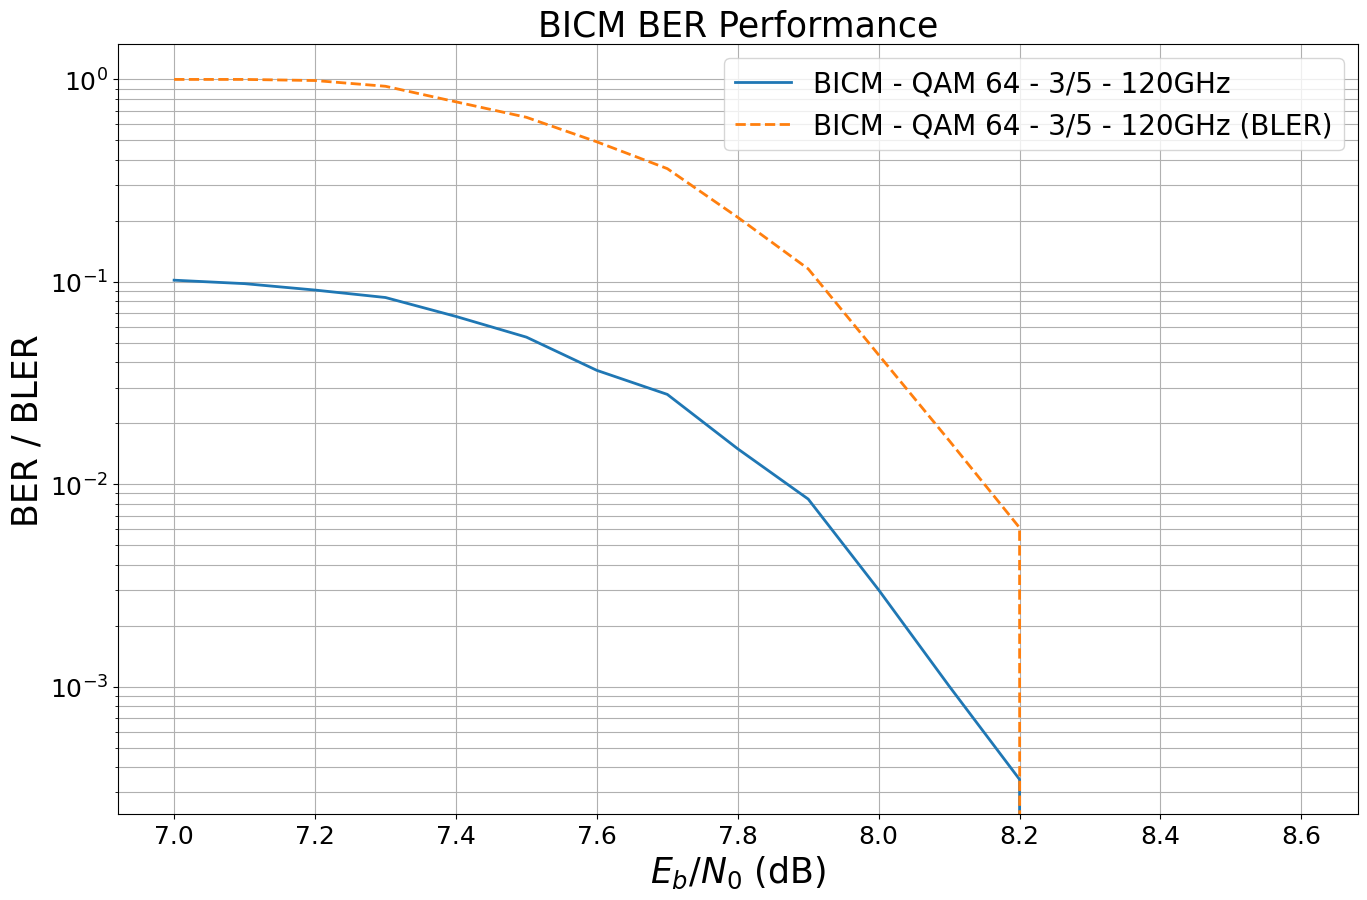

In [42]:
ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(7.0, 8.7, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend="BICM - QAM 64 - 3/5 - 120GHz",
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=10000,
                          num_target_block_errors=50,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

In [45]:
ber_plot_bicm.ber[0]

<tf.Tensor: shape=(17,), dtype=float32, numpy=
array([ 1.0188272e-01,  9.7953960e-02,  9.1057099e-02,  8.3656125e-02,
        6.7461416e-02,  5.3303756e-02,  3.6524348e-02,  2.7791280e-02,
        1.4963134e-02,  8.4474375e-03,  3.0062725e-03,  1.0068768e-03,
        3.4803775e-04, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00], dtype=float32)>

In [46]:
ber_plot_bicm.ber[1]

<tf.Tensor: shape=(17,), dtype=float32, numpy=
array([ 1.        ,  1.        ,  0.9875    ,  0.925     ,  0.775     ,
        0.65      ,  0.49166667,  0.3625    ,  0.20833333,  0.11590909,
        0.04354839,  0.01644737,  0.00609756, -1.        , -1.        ,
       -1.        , -1.        ], dtype=float32)>

In [47]:
ber_plot_bicm.snr[0]

array([7. , 7.1, 7.2, 7.3, 7.4, 7.5, 7.6, 7.7, 7.8, 7.9, 8. , 8.1, 8.2,
       8.3, 8.4, 8.5, 8.6])

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.6 | 1.2075e-01 | 1.0000e+00 |       46949 |      388800 |           40 |          40 |         3.2 |reached target block errors
      5.7 | 1.1736e-01 | 1.0000e+00 |       45629 |      388800 |           40 |          40 |         0.3 |reached target block errors
      5.8 | 1.1570e-01 | 1.0000e+00 |       44986 |      388800 |           40 |          40 |         0.3 |reached target block errors
      5.9 | 1.1292e-01 | 1.0000e+00 |       43905 |      388800 |           40 |          40 |         0.3 |reached target block errors
      6.0 | 1.0853e-01 | 1.0000e+00 |       42196 |      388800 |           40 |          40 |         0.3 |reached target block errors
      6.1 | 1.0503e-01 | 1.0000e+00 |       40835 |      388800 |

(<tf.Tensor: shape=(19,), dtype=float32, numpy=
 array([1.20753601e-01, 1.17358536e-01, 1.15704730e-01, 1.12924382e-01,
        1.08528808e-01, 1.05028294e-01, 1.03436217e-01, 9.83076096e-02,
        9.21244845e-02, 8.45961943e-02, 6.73276782e-02, 3.78935188e-02,
        1.27494857e-02, 4.74922825e-03, 9.36213997e-04, 5.16326290e-05,
        2.14974506e-07, 8.75219683e-08, 0.00000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(19,), dtype=float32, numpy=
 array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 9.7500002e-01, 8.5000002e-01, 5.2499998e-01,
        2.7500001e-01, 8.1249997e-02, 1.6666668e-02, 2.3364485e-03,
        7.4626866e-04, 2.7442371e-04, 0.0000000e+00], dtype=float32)>)

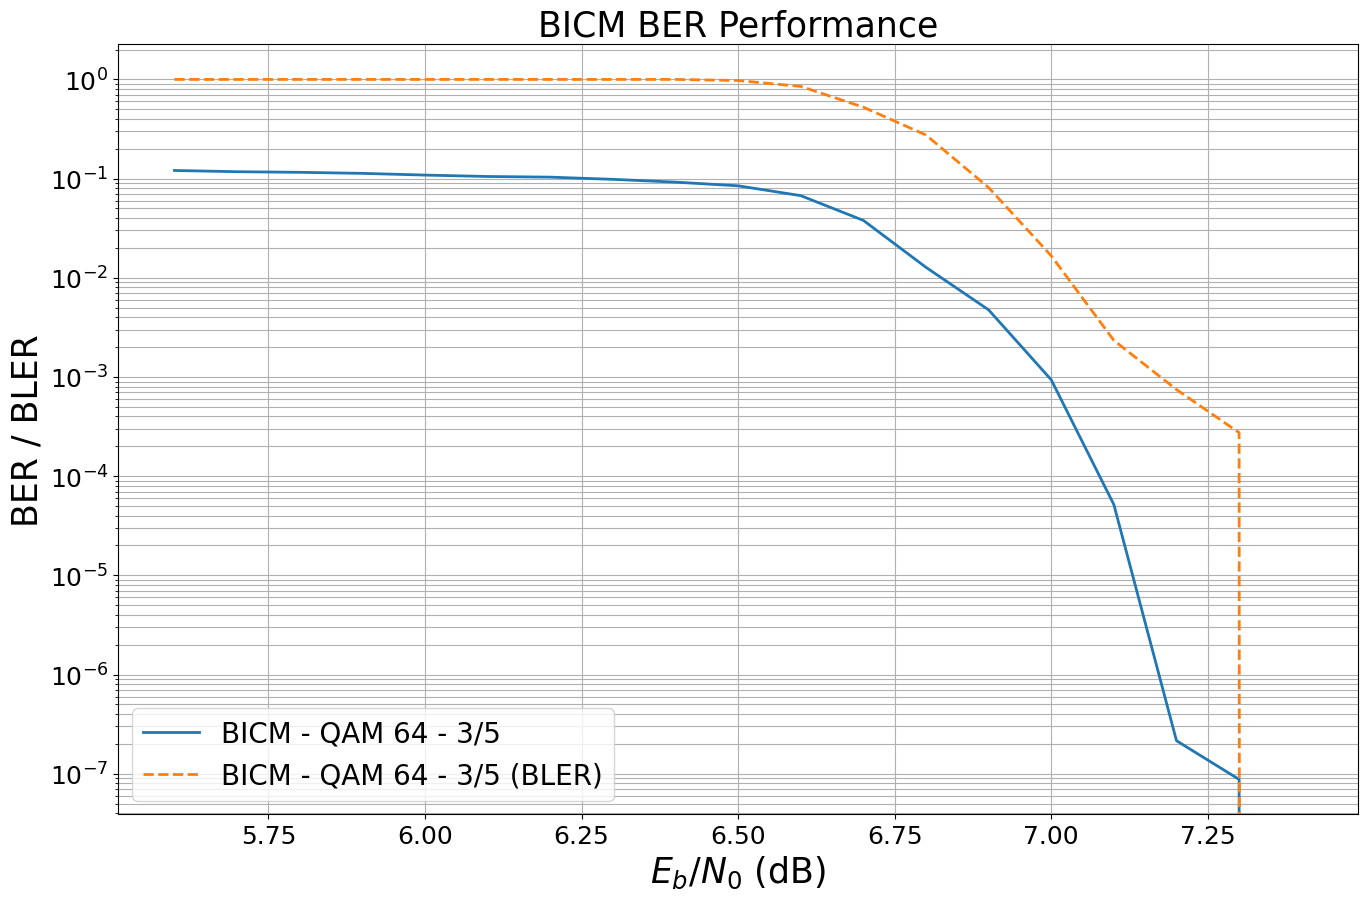

In [7]:
print(ber_plot_bicm.ber)
print(ber_plot_bicm.snr)
print(ber_plot_bicm.legend)

[<tf.Tensor: shape=(19,), dtype=float32, numpy=
array([1.20753601e-01, 1.17358536e-01, 1.15704730e-01, 1.12924382e-01,
       1.08528808e-01, 1.05028294e-01, 1.03436217e-01, 9.83076096e-02,
       9.21244845e-02, 8.45961943e-02, 6.73276782e-02, 3.78935188e-02,
       1.27494857e-02, 4.74922825e-03, 9.36213997e-04, 5.16326290e-05,
       2.14974506e-07, 8.75219683e-08, 0.00000000e+00], dtype=float32)>, <tf.Tensor: shape=(19,), dtype=float32, numpy=
array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
       1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
       1.0000000e+00, 9.7500002e-01, 8.5000002e-01, 5.2499998e-01,
       2.7500001e-01, 8.1249997e-02, 1.6666668e-02, 2.3364485e-03,
       7.4626866e-04, 2.7442371e-04, 0.0000000e+00], dtype=float32)>]
[array([5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8,
       6.9, 7. , 7.1, 7.2, 7.3, 7.4]), array([5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8,
       6.9, 7. , 7.1, 7.2,

## Probabilistic Amplitude Shaping (PAS)

In [8]:
import tensorflow as tf
from tensorflow.keras import Model
import ccdm
import numpy as np
import h5py
from scipy.sparse import csr_matrix
from ccdm_initialize import initialize
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder
from sionna.phy.utils import ebnodb2no, PlotBER
from sionna.phy.channel import AWGN
from end_to_end_model import generate_ldpc_H_matrix

In [10]:
class PAS_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, const_symbol_points, p_basic):
        super().__init__()

        self.batch_size = 1
        self.num_bits_per_symbol = 6
        self.parity_k = 2 # Two bits represent parity bits, other four represent information

        r = 2/3   # m = 6 so (m-2)/m rate code is required here
        self.k_ldpc = 10800
        n_ldpc = 16200
        self.n_out = 2700
        
        self.binary_source = BinarySource()

        parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
        self.H_sparse = csr_matrix(parity_matrix[:, :self.k_ldpc])
        
        # p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
        #  0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
        #  0.02854129, 0.06747344, 0.13703237, 0.12361801])
        
        [p_quant,self.k_input,self.n_i] = initialize(p_basic,self.n_out)
        
        probabilities = np.tile(p_basic,(1,(2**self.parity_k)))/(2**self.parity_k)
        power = np.sum(probabilities * np.abs(const_symbol_points)**2)
        normalized_points = const_symbol_points / np.sqrt(power)
        
        self.channel = AWGN()
        constellation = Constellation("custom", num_bits_per_symbol=6, points = normalized_points)
        self.mapper = Mapper(constellation=constellation)
        self.demapper = Demapper("app", constellation=constellation) # APP demapper
        
        num_bp_iter = 50
        llr_max_value = 120
        
        self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                cn_update="boxplus-phi", # use the exact boxplus function
                                num_iter=num_bp_iter,
                                llr_max=llr_max_value,
                               hard_out=True)
        
        bit_labels = np.array([[int(b) for b in format(i, f'0{6}b')] for i in range(64)])
        p_b1 = np.reshape(np.matmul(probabilities,bit_labels),(-1))
        self.prior = np.log(p_b1 / (1.0 - p_b1))
        
        self.bit_positions = np.arange((self.num_bits_per_symbol-self.parity_k)-1, -1, -1)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = self.n_out+ 4*32
        bandwidth = 960e3*4096
        fc = 120e9
        samples = 4*(block_size_ptrs+32)

        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size_ptrs, tf.int32))

        path_to_mat = "PreloadedMats/ptrs_CAZAC_4_32.mat"

        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots,batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    # No Graph execution possible due to sequential CCDM Encode and Decode
    # Due to this no attempt was made to use tensorflow implementation
    def __call__(self, batch_size, ebno_db):
        no = ebnodb2no(ebno_db,
                       num_bits_per_symbol=3.62,
                       coderate=1)

        b_stream = np.array(self.binary_source([self.k_input]),np.int64)
        code_symbols = np.array(ccdm.encode(b_stream, self.n_out, self.n_i))
        reverse_map = (((code_symbols[:, None]-1) & (1 << np.arange(self.num_bits_per_symbol-self.parity_k)[::-1])) > 0).astype(int)
        enc_input = np.reshape(reverse_map,((self.num_bits_per_symbol-self.parity_k)*self.n_out))
        parity_bits = self.H_sparse.dot(enc_input) % 2  # mod 2 because XOR over GF(2)
        parity_bits = np.mod(np.cumsum(parity_bits) , 2)
        parity_reshaped = np.reshape(parity_bits,(-1,self.parity_k))
        mapper_input_matrix = np.concatenate((parity_reshaped,reverse_map),axis=1)
        mapper_input = np.reshape(mapper_input_matrix,(self.num_bits_per_symbol*self.n_out))
        x = self.mapper(mapper_input)

        #########################

        ptrs_x_mod = self.ptrs_adder(tf.expand_dims(x,axis=0))

        x_up = self.upsampler(ptrs_x_mod)
        x_tx_filt = self.tx_filter(x_up)
        pn_out, _, _ = self.pn_tx(x_tx_filt)
        y_channel = self.channel(pn_out, no)
        y_channel_pn, _, _ = self.pn_rx(y_channel)
        y_rx_filt = self.rx_filter(y_channel_pn)
        y = self.downsampler(y_rx_filt)
        # print('y.shape: ',y.shape)
        _, y_data_vec = self.pn_compensate(y)

        #########################
        # # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
        # # print('meansquare',mean_squared.numpy())
        # y = self.channel(x, no)
        llr_ch = self.demapper(y_data_vec, no, self.prior)
        llr_reshaped = np.reshape(llr_ch,(-1,self.num_bits_per_symbol))
        llr_parity_comp = np.reshape(llr_reshaped[:,:self.parity_k],(-1))
        llr_amplitude_comp = np.reshape(llr_reshaped[:,self.parity_k:],(-1))
        codeword_llr = np.hstack((llr_amplitude_comp, llr_parity_comp))
        decoded_bits = tf.cast(self.decoder(codeword_llr),tf.int64).numpy()
        info_bits_reshaped = np.reshape(decoded_bits[:self.k_ldpc],(-1,self.num_bits_per_symbol-self.parity_k))
        # Use bitwise left shift to compute powers of two
        shifted_bits = info_bits_reshaped << self.bit_positions
        # Compute the integer representation using bitwise operations
        code_symbols_retrieved = np.sum(shifted_bits, axis=-1)+1
        # tf.print('ccdm input: ', code_symbols_retrieved.shape)
        decoded_bits_ccdmdec = ccdm.decode(code_symbols_retrieved, self.n_i, self.k_input)
        missing = self.k_input - len(decoded_bits_ccdmdec)
        if missing > 0:
            decoded_bits_ccdmdec.extend([0] * missing)
        # tf.print('ccdm :',np.array(decoded_bits_ccdmdec).shape)
        # tf.print('b_stream :',b_stream.shape)

        return b_stream, decoded_bits_ccdmdec


In [107]:
p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
 0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
 0.02854129, 0.06747344, 0.13703237, 0.12361801])

In [20]:
pas_model = PAS_scheme(1, 50, symbol_points_qam64, p_basic) # For testing

In [21]:
pas_model.k_input

9719

In [22]:
ebno_dbs = np.array([5.6]) # For testing

In [23]:
b_stream, decoded_bits = pas_model(1,ebno_dbs) # For testing

In [111]:
np.array(decoded_bits).shape

(9719,)

In [112]:
decoded_bits.shape

AttributeError: 'list' object has no attribute 'shape'

In [100]:
b_stream.shape

TensorShape([40, 9720])

In [19]:
pas_model.k_input # For testing

9719

In [21]:
np.array_equal(decoded_bits, b_stream)  # For testing

True

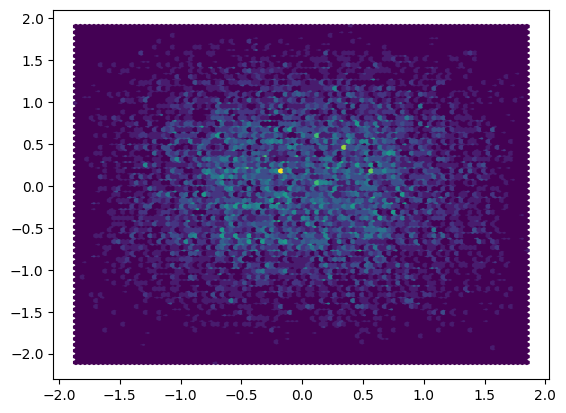

In [63]:
import matplotlib.pyplot as plt  # For testing

plt.hexbin(np.real(y_output),np.imag(y_output))

plt.show()

In [136]:
ber_plot_bicm = PlotBER("BICM BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.2 | 4.9989e-01 | 1.0000e+00 |       48584 |       97190 |           10 |          10 |         8.7 |reached target block errors
      6.3 | 4.9276e-01 | 1.0000e+00 |       47891 |       97190 |           10 |          10 |         8.9 |reached target block errors
      6.4 | 4.9577e-01 | 1.0000e+00 |       48184 |       97190 |           10 |          10 |         8.8 |reached target block errors
      6.5 | 4.9264e-01 | 1.0000e+00 |       47880 |       97190 |           10 |          10 |         8.8 |reached target block errors
      6.6 | 4.5340e-01 | 9.0909e-01 |       48473 |      106909 |           10 |          11 |         9.6 |reached target block errors
      6.7 | 3.2891e-01 | 7.1429e-01 |       44754 |      136066 |

(<tf.Tensor: shape=(13,), dtype=float32, numpy=
 array([0.4998868 , 0.49275646, 0.49577117, 0.49264327, 0.4534043 ,
        0.3289139 , 0.37595668, 0.1992789 , 0.11125728, 0.04005019,
        0.01472028, 0.00933144, 0.00082761], dtype=float32)>,
 <tf.Tensor: shape=(13,), dtype=float32, numpy=
 array([1.        , 1.        , 1.        , 1.        , 0.90909094,
        0.71428573, 0.7692308 , 0.41666666, 0.23809524, 0.08849557,
        0.03322259, 0.02079002, 0.00179986], dtype=float32)>)

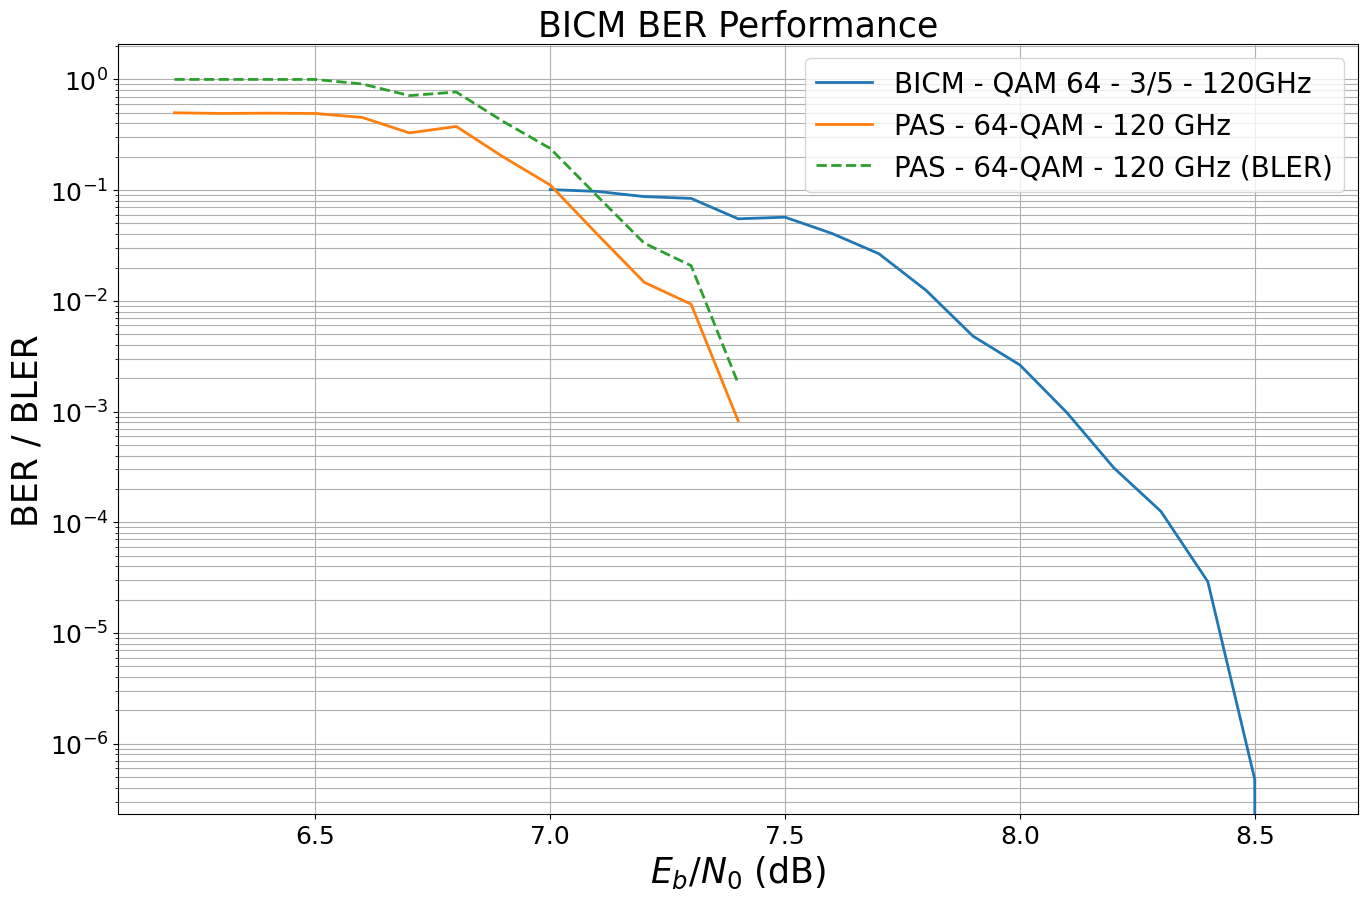

In [24]:
ber_plot_bicm.simulate(pas_model, # the function have defined previously
                          ebno_dbs=np.arange(6.20, 7.5, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend="PAS - 64-QAM - 120 GHz",
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=10000,
                          num_target_block_errors=10,
                          batch_size=1,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.6 | 4.9789e-01 | 1.0000e+00 |       48390 |       97190 |           10 |          10 |         8.9 |reached target block errors
      5.7 | 4.9435e-01 | 1.0000e+00 |       48046 |       97190 |           10 |          10 |         8.7 |reached target block errors
      5.8 | 4.3040e-01 | 9.0909e-01 |       46014 |      106909 |           10 |          11 |         9.4 |reached target block errors
      5.9 | 3.6913e-01 | 7.6923e-01 |       46639 |      126347 |           10 |          13 |        11.0 |reached target block errors
      6.0 | 1.4411e-01 | 3.1250e-01 |       44818 |      311008 |           10 |          32 |        27.5 |reached target block errors
      6.1 | 4.9815e-02 | 1.0870e-01 |       44542 |      894148 |

(<tf.Tensor: shape=(15,), dtype=float32, numpy=
 array([ 4.9789074e-01,  4.9435127e-01,  4.3040344e-01,  3.6913422e-01,
         1.4410561e-01,  4.9815018e-02,  7.4418844e-03,  1.9268307e-04,
        -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
        -1.0000000e+00, -1.0000000e+00, -1.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(15,), dtype=float32, numpy=
 array([ 1.0000000e+00,  1.0000000e+00,  9.0909094e-01,  7.6923078e-01,
         3.1250000e-01,  1.0869565e-01,  1.6977929e-02,  4.4593087e-04,
        -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
        -1.0000000e+00, -1.0000000e+00, -1.0000000e+00], dtype=float32)>)

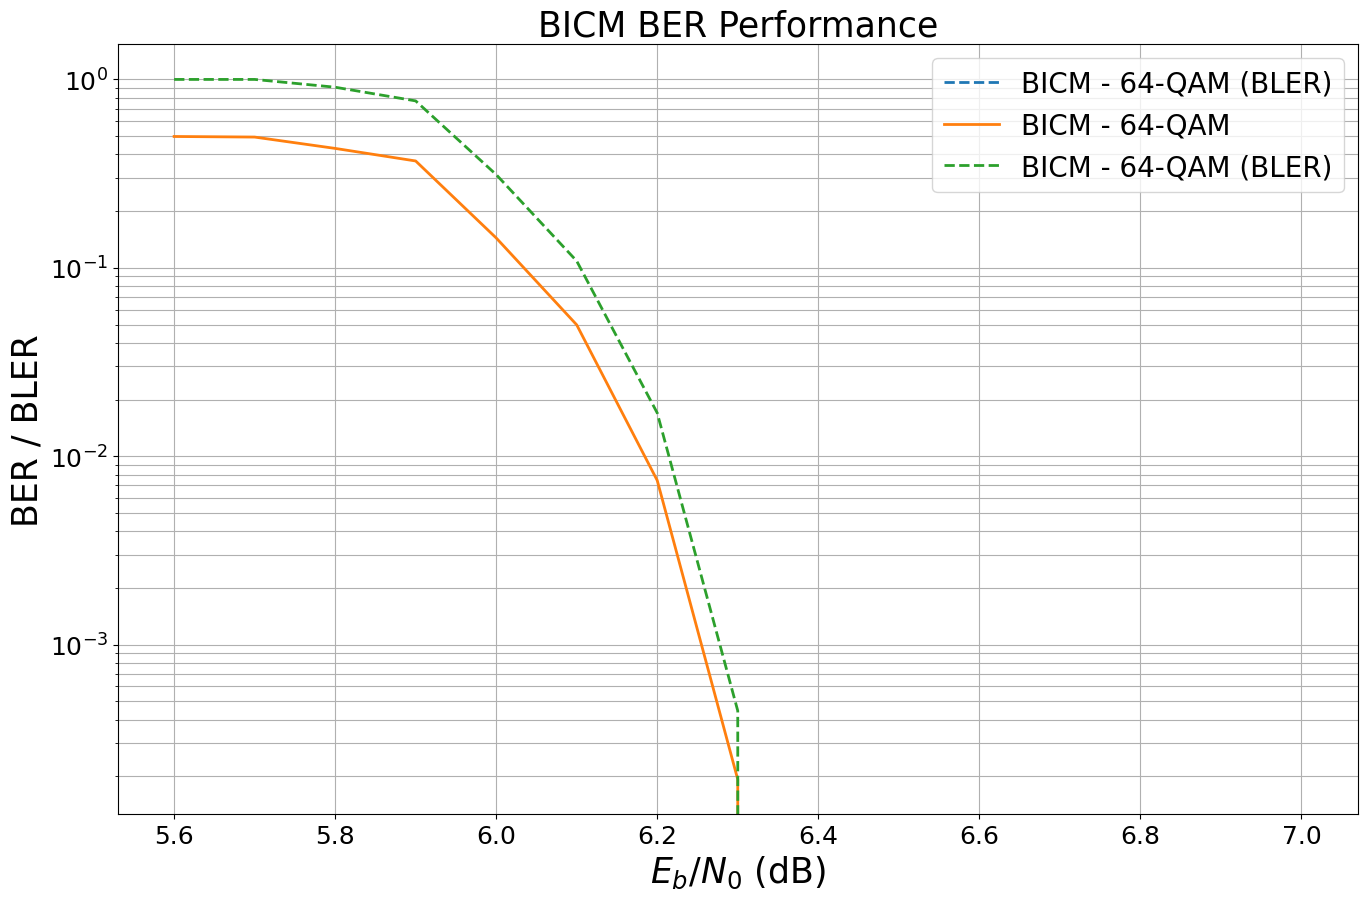

In [43]:
ber_plot_bicm.simulate(pas_model, # the function have defined previously
                          ebno_dbs=np.arange(5.60, 7.0, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend="PAS - 64-QAM",
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=10000,
                          num_target_block_errors=10,
                          batch_size=1,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

In [44]:
print(ber_plot_bicm.ber)
print(ber_plot_bicm.snr)
print(ber_plot_bicm.legend)

[<tf.Tensor: shape=(12,), dtype=float32, numpy=
array([ 0., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
      dtype=float32)>, <tf.Tensor: shape=(15,), dtype=float32, numpy=
array([ 4.9789074e-01,  4.9435127e-01,  4.3040344e-01,  3.6913422e-01,
        1.4410561e-01,  4.9815018e-02,  7.4418844e-03,  1.9268307e-04,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00], dtype=float32)>, <tf.Tensor: shape=(15,), dtype=float32, numpy=
array([ 1.0000000e+00,  1.0000000e+00,  9.0909094e-01,  7.6923078e-01,
        3.1250000e-01,  1.0869565e-01,  1.6977929e-02,  4.4593087e-04,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00], dtype=float32)>]
[array([6.4 , 6.45, 6.5 , 6.55, 6.6 , 6.65, 6.7 , 6.75, 6.8 , 6.85, 6.9 ,
       6.95]), array([5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8,
       6.9, 7. ]), array([5.6, 5.7

## Shannon SNR level

In [27]:
SE = 2.58
snr_value = 2**(SE)-1

In [28]:
shannon_ebno = 10*np.log10(snr_value/SE)
print(shannon_ebno)
shannon_esno = 10*np.log10(snr_value)
print(shannon_esno)

2.8555704687675503
6.971767528399853


## Step by Step testing of PAS

In [30]:
batch_size = 1

r = 2/3   # m = 6 so (m-2)/m rate code is required here
k_ldpc = 43200
n_ldpc = 64800
n_out = 10800


In [31]:
with h5py.File('check_mat.mat', 'r') as f:
    parity_matrix   = np.transpose(np.array(f['/p']))

H_sparse = csr_matrix(parity_matrix[:, :k_ldpc])

In [32]:
p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
 0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
 0.02854129, 0.06747344, 0.13703237, 0.12361801])

[p_quant,k_input,n_i] = initialize(p_basic,n_out)

In [82]:
print(n_i)
print(p_quant)
print(k_input)

[  67  174  361  319  169  369  800  722  333  750 1548 1336  308  729
 1480 1335]
[0.0062037  0.01611111 0.03342593 0.02953704 0.01564815 0.03416667
 0.07407407 0.06685185 0.03083333 0.06944444 0.14333333 0.1237037
 0.02851852 0.0675     0.13703704 0.12361111]
39076


In [83]:
binary_source = BinarySource()

In [84]:
b_stream = np.array(binary_source([k_input]),np.int64)

In [85]:
print(b_stream.shape)

(39076,)


In [86]:
%%time
code_symbols = np.array(ccdm.encode(b_stream, n_out, n_i))

CPU times: user 19.9 ms, sys: 0 ns, total: 19.9 ms
Wall time: 19.8 ms


In [87]:
print(code_symbols[:100])

[11 15 16  7 10 16 10 15 11 11 15 15 16  3 10  4  4 12  7  7 14 10  4 11
 15  3 11 16 16 12 10  3  6 15 12 10 11 14  7  7  7 14  2  6  8 12 16 16
  7 16  1 11 16  7 11 10 11 11 10 16 16 15 15  7 10 10 11 15 15 15  8 12
 11 12  7  1 16 11 15 15  8 10 14 13  6 16 12 15  8 12 16 16 10  9  5  8
 15 16 15 14]


In [88]:
print(code_symbols.shape)

(10800,)


In [89]:
reverse_map = (((code_symbols[:, None]-1) & (1 << np.arange(4)[::-1])) > 0).astype(int)


In [90]:
print(reverse_map[:5,:])

[[1 0 1 0]
 [1 1 1 0]
 [1 1 1 1]
 [0 1 1 0]
 [1 0 0 1]]


In [91]:
enc_input = np.reshape(reverse_map,(4*10800))

In [92]:
print(enc_input[:8])

[1 0 1 0 1 1 1 0]


In [93]:
# Compute p_alternative using sparse matrix-vector multiplication
parity_bits = H_sparse.dot(enc_input) % 2  # mod 2 because XOR over GF(2)
# Cumulative XOR
parity_bits = np.mod(np.cumsum(parity_bits) , 2)


In [94]:
parity_reshaped = np.reshape(parity_bits,(-1,2))

In [95]:
mapper_input_matrix = np.concatenate((parity_reshaped,reverse_map),axis=1)

In [96]:
print(mapper_input_matrix[:5,:])

[[1 0 1 0 1 0]
 [0 1 1 1 1 0]
 [1 0 1 1 1 1]
 [0 1 0 1 1 0]
 [0 0 1 0 0 1]]


In [97]:
mapper_input = np.reshape(mapper_input_matrix,(6*10800))

In [98]:
probabilities = np.tile(p_basic,(1,4))/4
power = np.sum(probabilities * np.abs(symbol_points)**2)
normalized_points = symbol_points / np.sqrt(power)

no = ebnodb2no(9,
               num_bits_per_symbol=6,
               coderate=2/3)

channel = AWGN()
constellation = Constellation("custom", num_bits_per_symbol=6, points = normalized_points)
mapper = Mapper(constellation=constellation)
demapper = Demapper("app", constellation=constellation) # APP demapper

In [99]:
bit_labels = np.array([[int(b) for b in format(i, f'0{6}b')] for i in range(64)])
print(bit_labels.shape)
print(probabilities.shape)

(64, 6)
(1, 64)


In [100]:
p_b1 = np.reshape(np.matmul(probabilities,bit_labels),(-1))

In [101]:
prior = np.log(p_b1 / (1.0 - p_b1))
print(prior)

[-5.99999998e-08 -5.99999998e-08  9.64071168e-01  1.90307813e-01
  1.00264236e+00  1.23316475e-01]


In [102]:
x = mapper(mapper_input) # map to symbol (QPSK)
# mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
# print('meansquare',mean_squared.numpy())
y = channel(x, no) # transmit over AWGN channel

In [103]:
llr_ch = demapper(y, no, prior) # Need to implement the prior value
print(llr_ch.shape)

(64800,)


In [104]:
llr_reshaped = np.reshape(llr_ch,(-1,6))

In [105]:
llr_parity_comp = np.reshape(llr_reshaped[:,:2],(-1))
llr_amplitude_comp = np.reshape(llr_reshaped[:,2:],(-1))

print(llr_parity_comp.shape)
print(llr_amplitude_comp.shape)

(21600,)
(43200,)


In [106]:
codeword_llr = np.hstack((llr_amplitude_comp, llr_parity_comp))

In [107]:
print(codeword_llr)

[ 10.332426    1.3557982  14.069973  ... -12.671761   -2.731142
  -2.404481 ]


In [108]:
decoded_bits = tf.cast(decoder(codeword_llr),tf.int64).numpy() # run LDPC decoder (incl. de-rate-matching)

In [109]:
info_bits_reshaped = np.reshape(decoded_bits[:k_ldpc],(-1,4))

In [110]:
print(decoded_bits.shape)

(64800,)


In [111]:
print(decoded_bits[k_ldpc:k_ldpc+20])

[1 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0]


In [112]:
print(parity_bits[:20])

[1 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0]


In [113]:
np.array_equal(parity_bits, decoded_bits[k_ldpc:])

True

In [114]:
bit_positions = np.arange(4-1, -1, -1)

In [119]:
# Use bitwise left shift to compute powers of two
shifted_bits = info_bits_reshaped << bit_positions  # same as np.left_shift(bits, self._bit_positions)

# Compute the integer representation using bitwise operations
code_symbols_retrieved = np.sum(shifted_bits, axis=-1)+1


In [120]:
print(code_symbols_retrieved[:10])

[11 15 16  7 10 16 10 15 11 11]


In [117]:
print(code_symbols[:10])

[11 15 16  7 10 16 10 15 11 11]


In [ ]:
### Do a modulation here....

In [121]:
## CCDM Decode
decoded_bits = ccdm.decode(code_symbols_retrieved, n_i, k_input)

In [122]:
### Finally compare sent bits with received...
np.array_equal(decoded_bits, b_stream)

True

In [52]:
num_bp_iter = 50
llr_max_value = 120


In [53]:
decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                        cn_update="boxplus-phi", # use the exact boxplus function
                        num_iter=num_bp_iter,
                        llr_max=llr_max_value,
                       hard_out=True)

In [74]:
%%time
decoded_bits = ccdm.decode(code_symbols, n_i, k_input)


CPU times: user 29.4 ms, sys: 0 ns, total: 29.4 ms
Wall time: 29.2 ms


In [44]:
np_src_symbols = np.array(b_stream)
np_dec_bits = np.array(decoded_bits)
np.array_equal(np_src_symbols, np_dec_bits)

True

## Computing information bits per symbol (SE)

In [4]:
def entropy(pdf, base=2):
    pdf = np.asarray(pdf, dtype=np.float64)
    pdf = pdf[pdf > 0]  # remove zero entries to avoid log(0)
    pdf /= np.sum(pdf)  # normalize to ensure valid probability distribution

    H = -np.sum(pdf * np.log(pdf) / np.log(base))
    return H


In [5]:
p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
 0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
 0.02854129, 0.06747344, 0.13703237, 0.12361801])

In [6]:
print(entropy(p_basic))

3.6261609412867566


In [12]:
p_all = np.hstack([p_basic, p_basic, p_basic, p_basic])/4

In [13]:
p_all

array([0.00155616, 0.00402213, 0.00836753, 0.00737793, 0.00391279,
       0.00854928, 0.01852054, 0.01670958, 0.00771134, 0.01735016,
       0.03584069, 0.03091558, 0.00713532, 0.01686836, 0.03425809,
       0.0309045 , 0.00155616, 0.00402213, 0.00836753, 0.00737793,
       0.00391279, 0.00854928, 0.01852054, 0.01670958, 0.00771134,
       0.01735016, 0.03584069, 0.03091558, 0.00713532, 0.01686836,
       0.03425809, 0.0309045 , 0.00155616, 0.00402213, 0.00836753,
       0.00737793, 0.00391279, 0.00854928, 0.01852054, 0.01670958,
       0.00771134, 0.01735016, 0.03584069, 0.03091558, 0.00713532,
       0.01686836, 0.03425809, 0.0309045 , 0.00155616, 0.00402213,
       0.00836753, 0.00737793, 0.00391279, 0.00854928, 0.01852054,
       0.01670958, 0.00771134, 0.01735016, 0.03584069, 0.03091558,
       0.00713532, 0.01686836, 0.03425809, 0.0309045 ])

In [41]:
print(entropy(p_all)) ## Includes 2 parity bits + [Spectral efficiency = Entropy of p_basic]

5.6261609412867575


In [26]:
snr_uniform = [4.5, 4.6, 4.7, 4.8, 4.9, 5.0, 5.1, 5.2, 5.3, 5.4, 5.5, 5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8,
       6.9, 7. , 7.1, 7.2, 7.3, 7.4]
snr_shaped = [4.5, 4.6, 4.7, 4.8, 4.9, 5.0, 5.1, 5.2, 5.3, 5.4, 5.5, 5.6, 5.7, 5.8, 5.9, 6. , 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8,
       6.9, 7. ]

bler_uniform = [ 1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,  1.0000000e+00, 1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,  1.0000000e+00,  8.0000001e-01,  6.9999999e-01,
        4.2500001e-01,  1.3750000e-01,  3.5714287e-02,  5.2884617e-03,
        1.0121458e-03,  3.8226301e-04, -1.0000000e+00]
bler_shaped = [ 1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,1.0000000e+00,  1.0000000e+00,  1.0000000e+00,  1.0000000e+00,
        1.0000000e+00,  1.0000000e+00, 1.0000000e+00,  1.0000000e+00,  9.0909094e-01,  7.6923078e-01,
        3.1250000e-01,  1.0869565e-01,  1.6977929e-02,  4.4593087e-04,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00]


## Plotting BLER curves

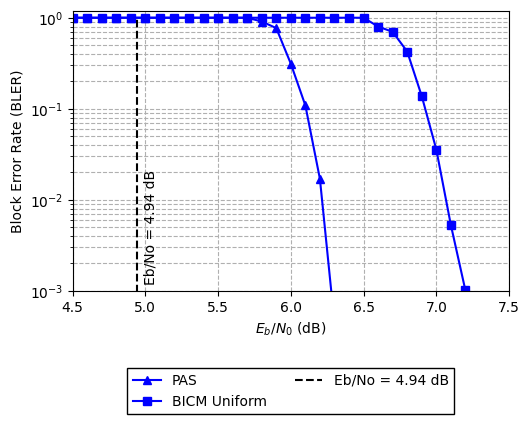

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt
import os

fig = plt.figure(figsize=(6, 4.5))

plt.semilogy(snr_shaped, bler_shaped, '^-', label='PAS', color='blue')
plt.semilogy(snr_uniform, bler_uniform, 's-', label='BICM Uniform' , color='blue')

plt.grid(True, which='both', linestyle='--')
plt.xlabel(r'$E_b/N_0$ (dB)')
plt.ylabel('Block Error Rate (BLER)')
plt.ylim( (10**-3,1.2*10**0) )
plt.xlim( (4.5,7.5) )
# Vertical dashed line with label
plt.vlines(x=4.94, ymin=0.00001, ymax=1.0, color='black', linestyles='dashed', label='Eb/No = 4.94 dB')

# Add the text label near the line
plt.text(4.94 + 0.05, 0.005, 'Eb/No = 4.94 dB', color='black', rotation=90, va='center')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25),
           ncol=2,frameon=True, fancybox=False, shadow=False,framealpha=1,edgecolor=(0, 0, 0, 0))
plt.tight_layout(rect=[0, 0, 0.9, 1.0])  # Adjust plot area to make space

plt.show()

### Using learned constellations

In [7]:
RESULTS_DIR = "Experiments_Feb/results_pn_prob_aware_120GHz"

snr_list = [13]
papr_list = [6.0, 6.5, 7.0, 7.5, 8.0]

ber_plot_ = PlotBER("BICM BER Performance")

for snr_db in snr_list:
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        plotname = f"papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
        points = data["constellation_points"]

        print(exp_name)
        # print(points)
        probabilities = data["constellation_probabilities"]
        prob_reshape = np.reshape(probabilities,[4,16])
        prob_basic_set = prob_reshape[0,:]
        print(entropy(prob_basic_set))
        # print(probabilities)
        # pas_model = PAS_scheme(1, 50, points, prob_basic_set)
        #
        # ber_plot_bicm.simulate(pas_model, # the function have defined previously
        #                           ebno_dbs=np.arange(3.0, 10.0, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
        #                           legend=plotname,
        #                           add_bler = False,
        #                           add_ber = True,
        #                           max_mc_iter=100,
        #                           num_target_block_errors=10,
        #                           batch_size=1,
        #                           soft_estimates=False,
        #                           early_stop=True,
        #                           show_fig=True,
        #                           forward_keyboard_interrupt=False)

snr_13_papr_6.0
3.5158809001294906
snr_13_papr_6.5
3.631576094441361
snr_13_papr_7.0
3.6521954896457522
snr_13_papr_7.5
3.7055232778604132
snr_13_papr_8.0
3.76793753972846


snr_13_papr_6.5
EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      3.0 | 5.0103e-01 | 1.0000e+00 |       48780 |       97360 |           10 |          10 |         8.8 |reached target block errors
      3.1 | 4.9826e-01 | 1.0000e+00 |       48511 |       97360 |           10 |          10 |         9.8 |reached target block errors
      3.2 | 5.0001e-01 | 1.0000e+00 |       48681 |       97360 |           10 |          10 |         9.2 |reached target block errors
      3.3 | 5.0077e-01 | 1.0000e+00 |       48755 |       97360 |           10 |          10 |         9.0 |reached target block errors
      3.4 | 5.0061e-01 | 1.0000e+00 |       48739 |       97360 |           10 |          10 |         9.0 |reached target block errors
      3.5 | 4.9978e-01 | 1.0000e+00 |       48659

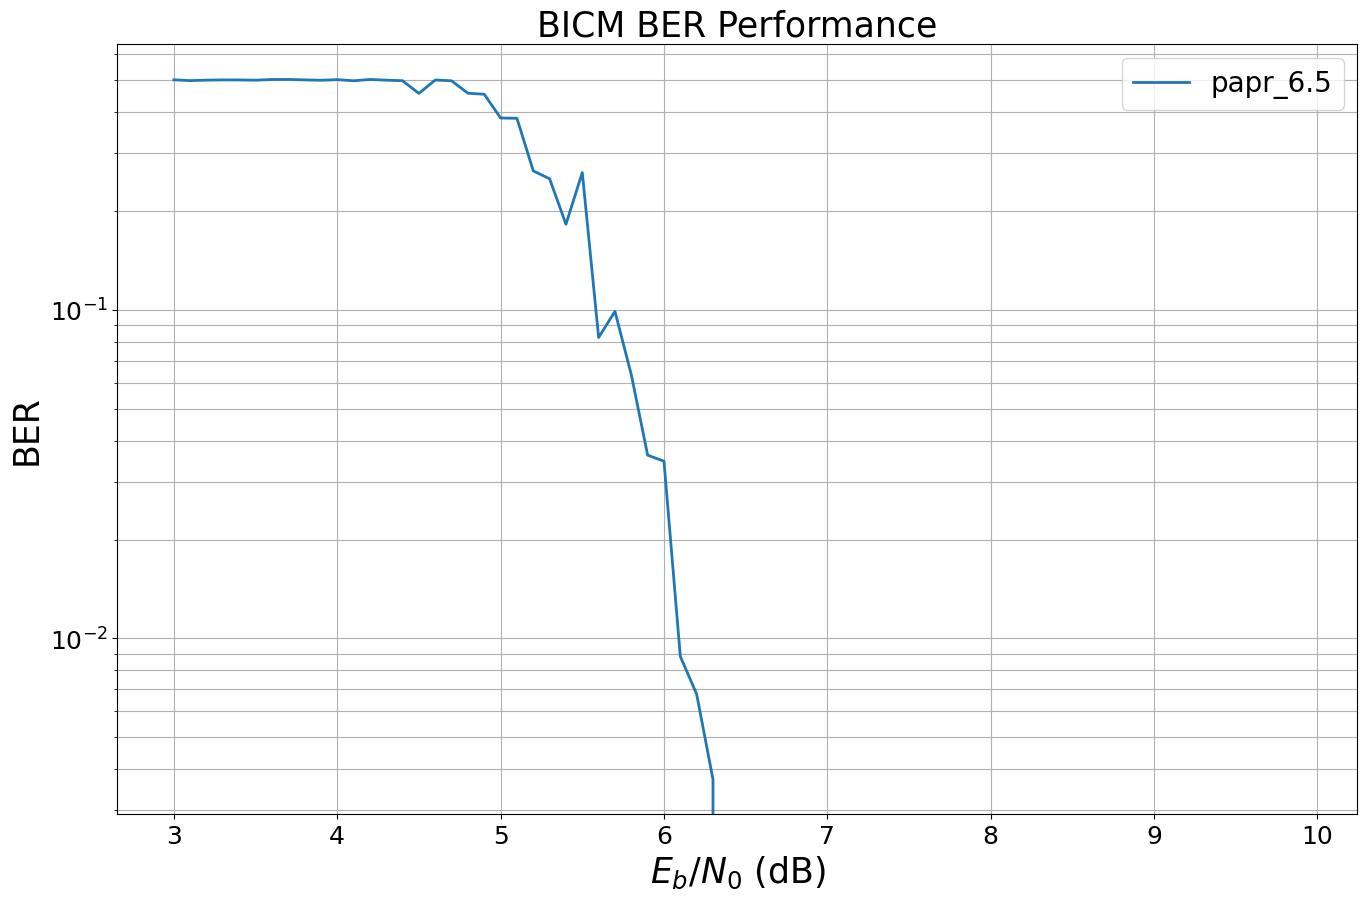

In [18]:
RESULTS_DIR = "Experiments_Feb/results_pn_prob_aware_120GHz"

snr_list = [13]
papr_list = [6.5]

ber_plot_ = PlotBER("BICM BER Performance")

for snr_db in snr_list:
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        plotname = f"papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
        points = data["constellation_points"]

        print(exp_name)
        # print(points)
        probabilities = data["constellation_probabilities"]
        prob_reshape = np.reshape(probabilities,[4,16])
        prob_basic_set = prob_reshape[0,:]
        # print(probabilities)
        pas_model = PAS_scheme(1, 50, points, prob_basic_set)

        ber_plot_.simulate(pas_model, # the function have defined previously
                                  ebno_dbs=np.arange(3.0, 10.0, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                                  legend=plotname,
                                  add_bler = False,
                                  add_ber = True,
                                  max_mc_iter=1000,
                                  num_target_block_errors=10,
                                  batch_size=1,
                                  soft_estimates=False,
                                  early_stop=True,
                                  show_fig=True,
                                  forward_keyboard_interrupt=False)

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 1.5188e-01 | 1.0000e+00 |      118105 |      777600 |           80 |          80 |         0.6 |reached target block errors
      5.1 | 1.5092e-01 | 1.0000e+00 |      117358 |      777600 |           80 |          80 |         0.6 |reached target block errors
      5.2 | 1.4819e-01 | 1.0000e+00 |      115229 |      777600 |           80 |          80 |         0.7 |reached target block errors
      5.3 | 1.4620e-01 | 1.0000e+00 |      113687 |      777600 |           80 |          80 |         0.6 |reached target block errors
      5.4 | 1.4369e-01 | 1.0000e+00 |      111737 |      777600 |           80 |          80 |         0.6 |reached target block errors
      5.5 | 1.4091e-01 | 1.0000e+00 |      109572 |      777600 |

(<tf.Tensor: shape=(50,), dtype=float32, numpy=
 array([ 1.51884004e-01,  1.50923356e-01,  1.48185447e-01,  1.46202415e-01,
         1.43694699e-01,  1.40910491e-01,  1.39251545e-01,  1.36917442e-01,
         1.35302216e-01,  1.32310957e-01,  1.29787803e-01,  1.26899436e-01,
         1.25802472e-01,  1.22784205e-01,  1.19224533e-01,  1.16694957e-01,
         1.13994345e-01,  1.11179270e-01,  1.08895317e-01,  1.04929268e-01,
         1.03019550e-01,  9.79925394e-02,  9.25218612e-02,  8.51440355e-02,
         7.56057128e-02,  6.02854937e-02,  4.68981490e-02,  2.90547833e-02,
         1.60438102e-02,  7.09935883e-03,  3.31424107e-03,  1.62405183e-03,
         4.84258635e-04,  1.27139559e-04,  5.61543020e-05, -1.00000000e+00,
        -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
        -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
        -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
        -1.00000000e+00, -1.00000000e+00

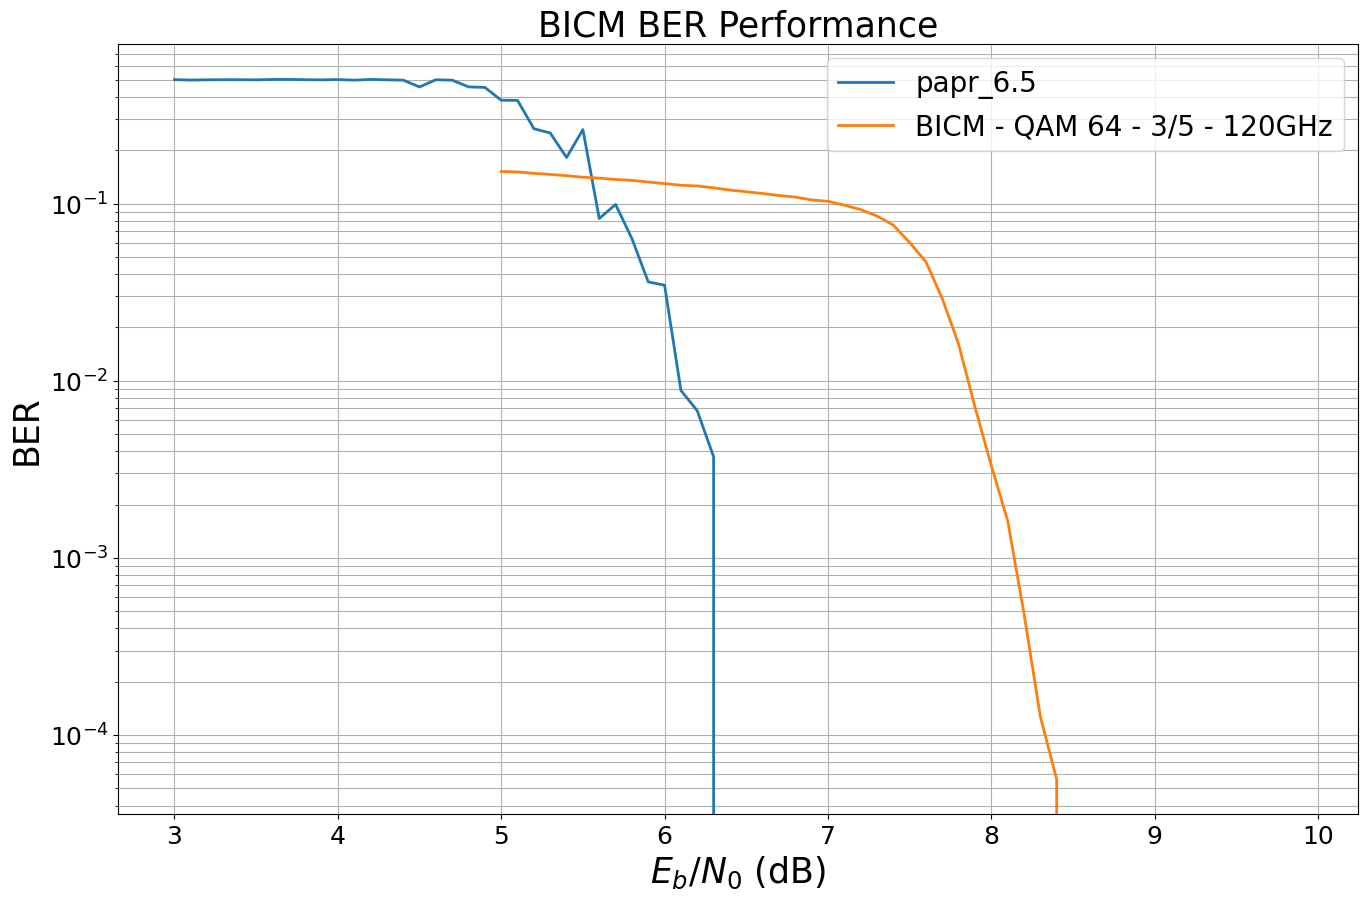

In [33]:
ber_plot_.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 10.0, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend="BICM - QAM 64 - 3/5 - 120GHz",
                          add_bler = False,
                          add_ber = True,
                          max_mc_iter=10000,
                          num_target_block_errors=50,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)

In [22]:
ber_plot_.ber

[<tf.Tensor: shape=(70,), dtype=float32, numpy=
 array([ 0.5010271 ,  0.49826416,  0.50001025,  0.50077033,  0.500606  ,
         0.4997843 ,  0.5021775 ,  0.5024548 ,  0.5007909 ,  0.49954808,
         0.5016639 ,  0.4977198 ,  0.5023418 ,  0.49988702,  0.49792522,
         0.4555819 ,  0.50051355,  0.4976068 ,  0.45612347,  0.45285538,
         0.38344607,  0.38264015,  0.26471478,  0.25051355,  0.1821571 ,
         0.26163343,  0.08237469,  0.09891537,  0.06345864,  0.03612768,
         0.03461959,  0.00881938,  0.00676965,  0.00372475, -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
        -1.        , -1.        , -1.        , -1.        , -1.        ,
   

In [104]:
prob_reshape

array([[0.00320509, 0.0056816 , 0.00806546, 0.00565002, 0.00445322,
        0.01119341, 0.01841395, 0.01668962, 0.0066334 , 0.01940473,
        0.03603319, 0.03170411, 0.00769809, 0.01695345, 0.03091062,
        0.02731005],
       [0.00320509, 0.0056816 , 0.00806546, 0.00565002, 0.00445322,
        0.01119341, 0.01841395, 0.01668962, 0.0066334 , 0.01940473,
        0.03603319, 0.03170411, 0.00769809, 0.01695345, 0.03091062,
        0.02731005],
       [0.00320509, 0.0056816 , 0.00806546, 0.00565002, 0.00445322,
        0.01119341, 0.01841395, 0.01668962, 0.0066334 , 0.01940473,
        0.03603319, 0.03170411, 0.00769809, 0.01695345, 0.03091062,
        0.02731005],
       [0.00320509, 0.0056816 , 0.00806546, 0.00565002, 0.00445322,
        0.01119341, 0.01841395, 0.01668962, 0.0066334 , 0.01940473,
        0.03603319, 0.03170411, 0.00769809, 0.01695345, 0.03091062,
        0.02731005]], dtype=float32)